In [1]:
import os
import numpy as np
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt
import EFC_learningfMRI.globals as gl
import EFC_learningfMRI.vis as vis
import EFC_learningfMRI.util as util

base directory found: /cifs/diedrichsen/data/Chord_exp
Atlas directory found: atlases
figure directory found: paper/figures/


# Noise ceilings
## Load data

In [2]:
H     = 'L'
atlas = 'ROI'
rois  = gl.rois[atlas]
glm   = 3
sns   = gl.participants
mc = pd.read_csv(os.path.join(gl.baseDir, gl.geomDir, f'model_correlation.within_session.{atlas}.glm{glm}.tsv'), sep='\t')
nc = mc.drop_duplicates(['sn', 'Hem', 'roi', 'session'])[['sn', 'Hem', 'roi', 'session', 'lower', 'upper']]
nc_long = nc.melt(id_vars=['sn', 'Hem', 'roi', 'session'], value_vars=['lower', 'upper'], var_name='bound', value_name='r')

# Upper and lower noise ceiling
The noise ceilings were defined as the mean correlation of each participant's crossnobis dissimilarities with the group mean (upper noise ceiling) or with the group mean of the other participants (lower noice ceiling). The noise ceilings were significantly >0 in all ROIs, suggesting consistent representational geometry across participants. The increasing gap between upper and lower noise ceiling across sessions reflect the fact that each participant practiced a different set of trained chords.

bound  roi  session         T  dof        p_val         CI95  cohen_d
lower  SMA        3  7.040736   15 3.999179e-06 [0.23, 0.44] 1.760184
lower  PMd        3 10.152530   15 4.093030e-08  [0.4, 0.62] 2.538132
lower  PMv        3  4.924660   15 1.833245e-04 [0.13, 0.34] 1.231165
lower   M1        3 10.039199   15 4.746084e-08 [0.39, 0.59] 2.509800
lower   S1        3 16.171637   15 6.683921e-11 [0.53, 0.69] 4.042909
lower SPLa        3  8.425421   15 4.523150e-07 [0.35, 0.59] 2.106355
lower SPLp        3 19.134178   15 5.985334e-12  [0.56, 0.7] 4.783545
lower  SMA        9  4.728909   15 2.689544e-04 [0.12, 0.33] 1.182227
lower  PMd        9  7.440140   15 2.079576e-06 [0.31, 0.55] 1.860035
lower  PMv        9  3.573568   15 2.771926e-03 [0.07, 0.27] 0.893392
lower   M1        9  7.264905   15 2.763410e-06  [0.3, 0.54] 1.816226
lower   S1        9  8.979529   15 2.019428e-07  [0.4, 0.66] 2.244882
lower SPLa        9  5.750509   15 3.833982e-05 [0.23, 0.51] 1.437627
lower SPLp        9 

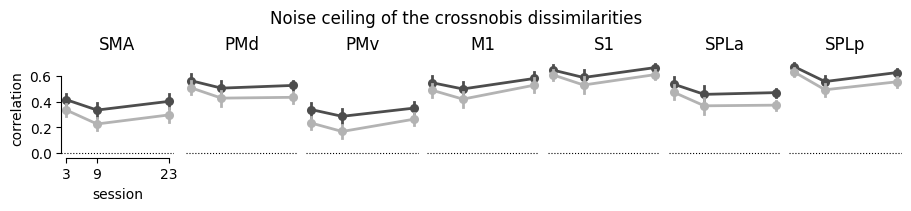

In [3]:
hue_order = ['upper', 'lower']
palette   = ['0.3', '0.7']

fig, axs = plt.subplots(1, len(rois), sharey=True, sharex=True, figsize=(9, 2), constrained_layout=True)

vis.plot_im_sess(fig, axs, nc_long[nc_long.Hem == H], rois, y='r', x='session', hue='bound',
             hue_order=hue_order, palette=palette, kind='point', dodge=0, add_zero=True, legend=False)
sb.despine(ax=axs[0], trim=True)
axs[0].set_ylabel('correlation')
axs[0].set_xlabel('session')

fig.suptitle(f'Noise ceiling of the crossnobis dissimilarities')

fig.savefig(os.path.join(gl.figDir, 'noise_ceiling_bounds.pdf'))

blocks = []
for bound in hue_order:
    t = util.ttest_im_sess(nc[nc.Hem == H], rois, y=bound, x='session')
    blocks.append(t.assign(bound=bound))          # tag the rows, so the blocks stay apart once stacked

ttest = pd.concat(blocks, ignore_index=True)
ttest = ttest.sort_values(by=['bound', 'session'], kind='stable')

print(ttest[['bound', 'roi', 'session', 'T', 'dof', 'p_val', 'CI95', 'cohen_d']].to_string(index=False))

plt.show()